# 01 · Modelo de escoamento bifásico: Beggs & Brill e balanço de momento

Este notebook apresenta os blocos de base do simulador: as propriedades dos fluidos
(Tabela 1 do artigo), o mapa de padrões de escoamento da correlação de Beggs & Brill
(1973) (Fig. 2) e a integração do balanço de momento ao longo de um duto (Eqs. 1–4 e 8–10).

Referência: de Souza, J.N.M., de Medeiros, J.L., Costa, A.L.H., Nunes, G.C. (2010).
*Modeling, simulation and optimization of continuous gas lift systems for deepwater
offshore petroleum production*. J. Pet. Sci. Eng., doi:10.1016/j.petrol.2010.03.028.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
FIG = ROOT / "docs" / "paper" / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

## Tabela 1 · Propriedades dos fluidos

In [2]:
from gaslift import FluidProperties, paper_fluid

fluid = paper_fluid()
table1 = pd.DataFrame(
    {
        "Oil": {"Density (kg/m³)": fluid.liquid_density, "Viscosity (Pa s)": fluid.liquid_viscosity,
                "Interfacial tension (N/m)": fluid.interfacial_tension},
        "Gas": {"Reference density (kg/m³)": fluid.gas_reference_density,
                "Normal density (kg/m³)": fluid.gas_normal_density,
                "Reference pressure (bar)": fluid.reference_pressure / 1e5,
                "Polytropic coefficient (-)": fluid.gas_polytropic_coefficient,
                "Viscosity (Pa s)": fluid.gas_viscosity},
    }
)
table1

,Oil,Gas
Density (kg/m³),850.000,NaN
Viscosity (Pa s),0.012,8.0000e-05
Interfacial tension (N/m),0.071,NaN
Reference density (kg/m³),NaN,8.0000e+01
Normal density (kg/m³),NaN,1.2000e+00
Reference pressure (bar),NaN,1.0000e+02
Polytropic coefficient (-),NaN,1.2500e+00


A massa específica do gás segue a relação politrópica $\rho_G = \rho_{G0}\,(P/P_0)^{1/\gamma}$;
o líquido é incompressível.

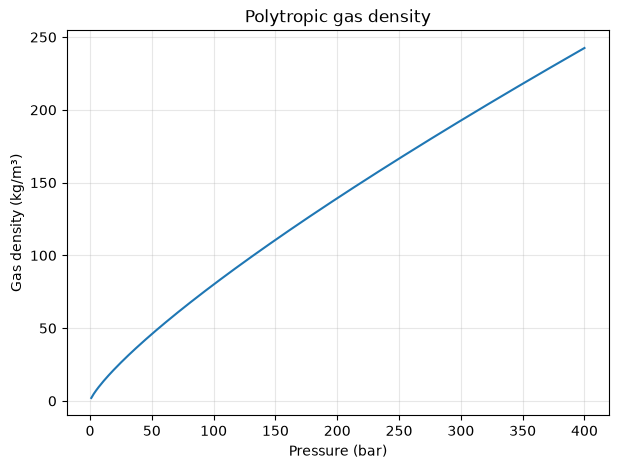

In [3]:
p = np.linspace(1e5, 400e5, 200)
plt.plot(p / 1e5, fluid.gas_density(p))
plt.xlabel("Pressure (bar)"); plt.ylabel("Gas density (kg/m³)"); plt.title("Polytropic gas density");

## Fig. 2 · Mapa de padrões de escoamento horizontal (Beggs & Brill)

Os testes lógicos da correlação original são substituídos por funções logísticas muito
abruptas (fator $10^6$), como no código MATLAB que gerou o artigo, para que o modelo seja
contínuo. O mapa abaixo é construído exatamente com essa função.

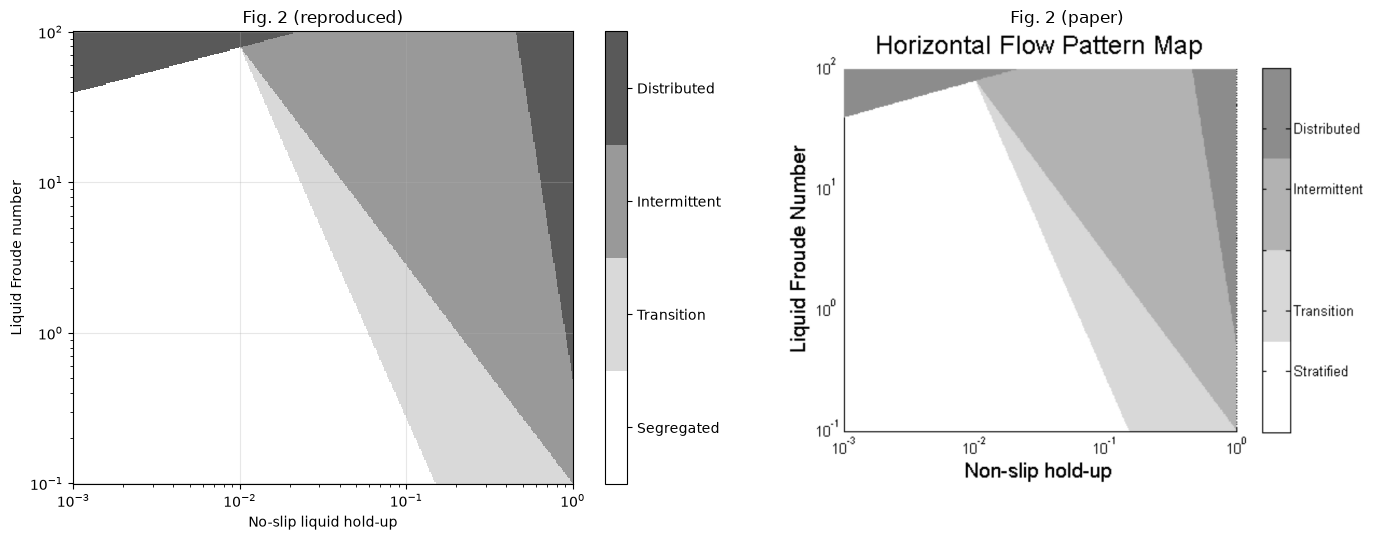

In [4]:
from gaslift.plotting import plot_flow_pattern_map

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
plot_flow_pattern_map(ax1)
ax1.set_title("Fig. 2 (reproduced)")
ax2.imshow(plt.imread(FIG / "FIG_02.png")); ax2.axis("off"); ax2.set_title("Fig. 2 (paper)")
plt.tight_layout()

## Hold-up e gradiente de pressão em um duto vertical

Para um duto de 4 in com 850 kg/m³ de óleo, o gradiente de pressão passa por um mínimo
quando a vazão de gás aumenta: o gás reduz a parcela hidrostática mas aumenta o atrito.
Esse é o mecanismo que produz a vazão ótima de injeção do gas lift.

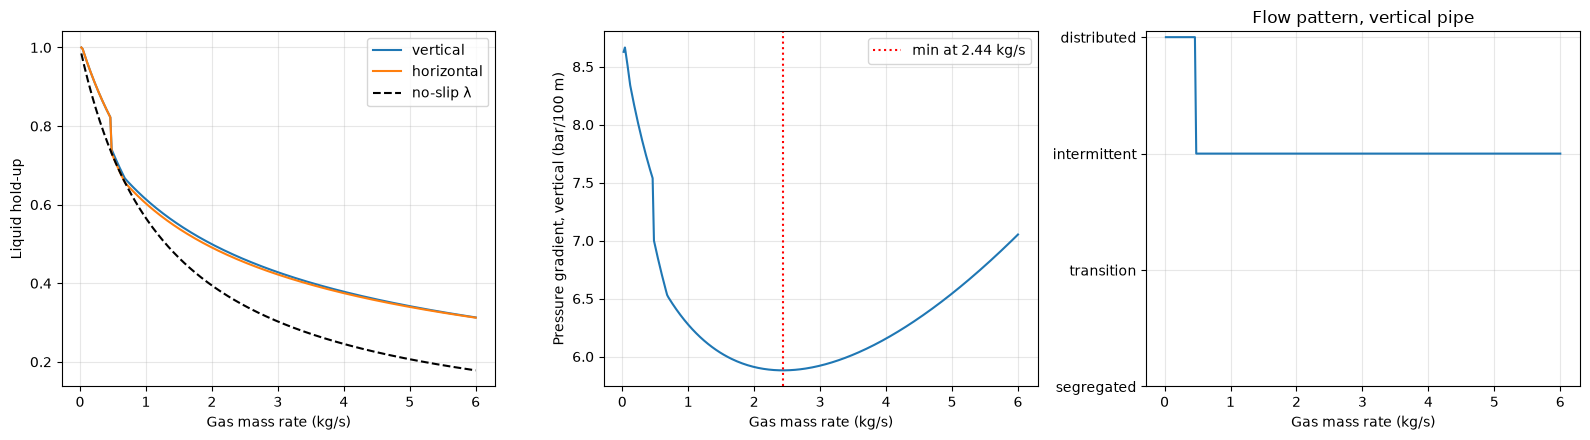

In [5]:
from gaslift.beggs_brill import closure_relations, PATTERN_NAMES
from gaslift.units import G, INCH

D = 4 * INCH
area = np.pi * D**2 / 4
pressure = 150e5
q_oil = 10.0  # kg/s
q_gas = np.linspace(0.02, 6.0, 300)
v_sl = np.full_like(q_gas, q_oil / (area * fluid.liquid_density))
v_sg = q_gas / (area * fluid.gas_density(pressure))
res_v = closure_relations(pressure, v_sl, v_sg, D, 100e-6, np.pi / 2, fluid)
res_h = closure_relations(pressure, v_sl, v_sg, D, 100e-6, 0.0, fluid)
grad_v = (res_v.mixture_density * G + 4 * res_v.shear_stress / D) / 1e5 * 100  # bar per 100 m
grad_h = (4 * res_h.shear_stress / D) / 1e5 * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(q_gas, res_v.liquid_holdup, label="vertical"); axes[0].plot(q_gas, res_h.liquid_holdup, label="horizontal")
axes[0].plot(q_gas, res_v.no_slip_holdup, "k--", label="no-slip λ")
axes[0].set_xlabel("Gas mass rate (kg/s)"); axes[0].set_ylabel("Liquid hold-up"); axes[0].legend()
axes[1].plot(q_gas, grad_v); axes[1].set_xlabel("Gas mass rate (kg/s)"); axes[1].set_ylabel("Pressure gradient, vertical (bar/100 m)")
axes[1].axvline(q_gas[np.argmin(grad_v)], color="r", ls=":", label=f"min at {q_gas[np.argmin(grad_v)]:.2f} kg/s"); axes[1].legend()
axes[2].plot(q_gas, res_v.pattern.index); axes[2].set_yticks([1, 2, 3, 4]); axes[2].set_yticklabels([PATTERN_NAMES[i] for i in (1, 2, 3, 4)])
axes[2].set_xlabel("Gas mass rate (kg/s)"); axes[2].set_title("Flow pattern, vertical pipe")
plt.tight_layout()

## Integração do balanço de momento em um duto (Eqs. 8–10)

Um poço vertical de 2000 m e 4 in produzindo 10 kg/s de óleo com 2 kg/s de gás, com
15 bar no topo. O modelo rigoroso integra $dP/dx$ nas duas direções (Dormand–Prince 5(4)
com o mesmo controle de passo do `ode45`) e usa a média das duas estimativas; o modelo
não rigoroso avalia o gradiente no ponto médio com a pressão média.

converged (residual below tolerance) after 11 iterations, |F| = 8.549e-14, 0.29 s
converged (residual below tolerance) after 3 iterations, |F| = 2.051e-10, 0.00 s
bottom pressure: rigorous 133.98 bar, non-rigorous 127.65 bar


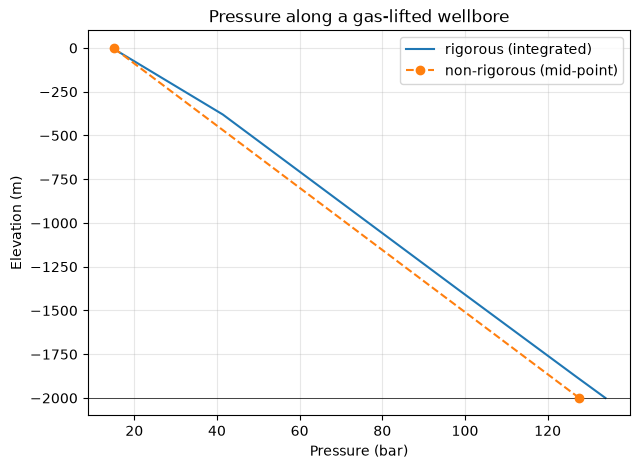

In [6]:
from gaslift import Network, NodeRole, Specifications, Simulator, SimulationOptions, ModelOptions

net = Network(fluid, "single vertical pipe")
net.add_node("bottom", 0, 0, -2000)
net.add_node("top", 0, 0, 0, NodeRole.OUTLET)
net.add_pipe("wellbore", "bottom", "top", diameter=4 * INCH, roughness=100e-6)
specs = Specifications(net).set_liquid_source("bottom", 10.0, 2.0).set_pressure("top", 15e5)

rigorous = Simulator(net, specs).solve()
nonrig = Simulator(net, specs, SimulationOptions(model=ModelOptions(rigorous=False), compute_profiles=False)).solve()
print(rigorous.status)
print(nonrig.status)
prof = rigorous.profile("wellbore")
plt.plot(prof["pressure_bar"], -2000 + prof["axial_position_m"], label="rigorous (integrated)")
plt.axhline(-2000, color="k", lw=0.5)
plt.plot([nonrig.pressure_bar("bottom"), nonrig.pressure_bar("top")], [-2000, 0], "o--", label="non-rigorous (mid-point)")
plt.xlabel("Pressure (bar)"); plt.ylabel("Elevation (m)"); plt.legend(); plt.title("Pressure along a gas-lifted wellbore")
print(f"bottom pressure: rigorous {rigorous.pressure_bar('bottom'):.2f} bar, non-rigorous {nonrig.pressure_bar('bottom'):.2f} bar")

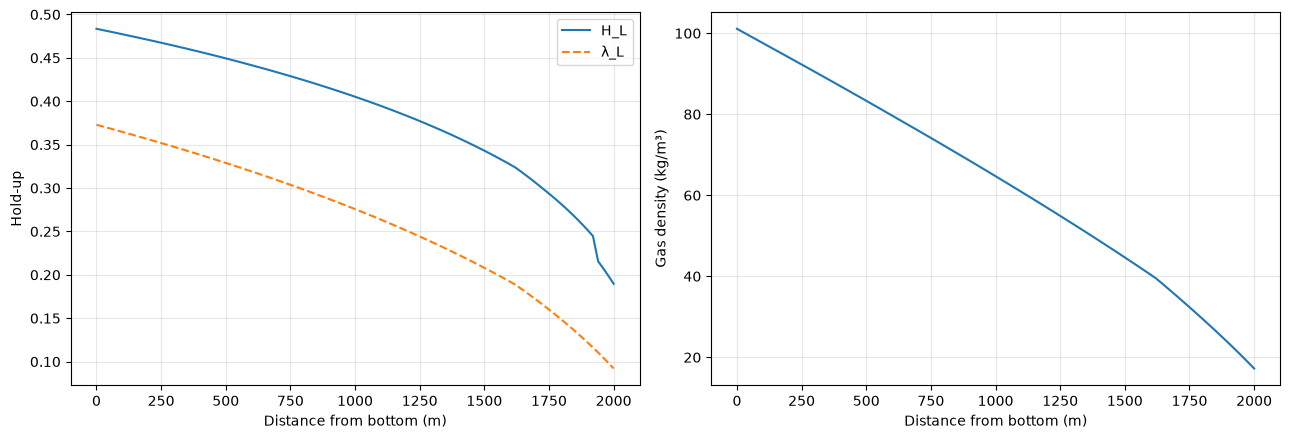

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(prof["axial_position_m"], prof["liquid_holdup"], label="H_L"); axes[0].plot(prof["axial_position_m"], prof["no_slip_holdup"], "--", label="λ_L")
axes[0].set_xlabel("Distance from bottom (m)"); axes[0].set_ylabel("Hold-up"); axes[0].legend()
axes[1].plot(prof["axial_position_m"], prof["gas_density_kg_m3"]); axes[1].set_xlabel("Distance from bottom (m)"); axes[1].set_ylabel("Gas density (kg/m³)")
plt.tight_layout()